In [107]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import  seaborn as sns
import re
import warnings

In [108]:
## Start of  Machine  Learning
from sklearn.model_selection  import  train_test_split

In [109]:
## LinearRegressions
from sklearn.linear_model import LinearRegression

In [110]:
## Preprocessing
from sklearn.preprocessing import StandardScaler,OneHotEncoder

In [111]:

## دى ي كبير هى المايسترو ال بيقسم البيانات ويقولك اشتغل على الارقام والنصوص  ي كببر
from sklearn.compose import ColumnTransformer

In [112]:
## ربط الموديل  مع ال Preprocessing
from sklearn.pipeline import Pipeline

In [113]:
## mertix
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error


In [114]:
##  طبع رساله الخطاء
warnings.filterwarnings('ignore')


In [115]:
## بقوله هنا  ي كبير  خلى الخلفيات بيضه  اشطا ي  دولى
sns.set_style("whitegrid")

In [116]:
##  دى علشان يثبط شكل الروسومات ي كبير
plt.rcParams["figure.figsize"]=(10,7)


In [117]:
print('Done')

Done


In [118]:
df=pd.read_csv('/content/sample_data/car details v4.csv')

In [87]:
df.head(10)

,Make,Model,Price,Year,Kilometer,Fuel Type,Transmission,Location,Color,Owner,Seller Type,Engine,Max Power,Max Torque,Drivetrain,Length,Width,Height,Seating Capacity,Fuel Tank Capacity
0,Honda,Amaze 1.2 VX i-VTEC,505000,2017,87150,Petrol,Manual,Pune,Grey,First,Corporate,1198 cc,87 bhp @ 6000 rpm,109 Nm @ 4500 rpm,FWD,3990.0,1680.0,1505.0,5.0,35.0
1,Maruti Suzuki,Swift DZire VDI,450000,2014,75000,Diesel,Manual,Ludhiana,White,Second,Individual,1248 cc,74 bhp @ 4000 rpm,190 Nm @ 2000 rpm,FWD,3995.0,1695.0,1555.0,5.0,42.0
2,Hyundai,i10 Magna 1.2 Kappa2,220000,2011,67000,Petrol,Manual,Lucknow,Maroon,First,Individual,1197 cc,79 bhp @ 6000 rpm,112.7619 Nm @ 4000 rpm,FWD,3585.0,1595.0,1550.0,5.0,35.0
3,Toyota,Glanza G,799000,2019,37500,Petrol,Manual,Mangalore,Red,First,Individual,1197 cc,82 bhp @ 6000 rpm,113 Nm @ 4200 rpm,FWD,3995.0,1745.0,1510.0,5.0,37.0
4,Toyota,Innova 2.4 VX 7 STR [2016-2020],1950000,2018,69000,Diesel,Manual,Mumbai,Grey,First,Individual,2393 cc,148 bhp @ 3400 rpm,343 Nm @ 1400 rpm,RWD,4735.0,1830.0,1795.0,7.0,55.0
5,Maruti Suzuki,Ciaz ZXi,675000,2017,73315,Petrol,Manual,Pune,Grey,First,Individual,1373 cc,91 bhp @ 6000 rpm,130 Nm @ 4000 rpm,FWD,4490.0,1730.0,1485.0,5.0,43.0
6,Mercedes-Benz,CLA 200 Petrol Sport,1898999,2015,47000,Petrol,Automatic,Mumbai,White,Second,Individual,1991 cc,181 bhp @ 5500 rpm,300 Nm @ 1200 rpm,FWD,4630.0,1777.0,1432.0,5.0,NaN
7,BMW,X1 xDrive20d M Sport,2650000,2017,75000,Diesel,Automatic,Coimbatore,White,Second,Individual,1995 cc,188 bhp @ 4000 rpm,400 Nm @ 1750 rpm,AWD,4439.0,1821.0,1612.0,5.0,51.0
8,Skoda,Octavia 1.8 TSI Style Plus AT [2017],1390000,2017,56000,Petrol,Automatic,Mumbai,White,First,Individual,1798 cc,177 bhp @ 5100 rpm,250 Nm @ 1250 rpm,FWD,4670.0,1814.0,1476.0,5.0,50.0
9,Nissan,Terrano XL (D),575000,2015,85000,Diesel,Manual,Mumbai,White,First,Individual,1461 cc,84 bhp @ 3750 rpm,200 Nm @ 1900 rpm,FWD,4331.0,1822.0,1671.0,5.0,50.0


In [88]:
##  يقولك فى كام صف وكام عمود
df.shape

(2059, 20)

In [89]:
##  بتجيب الاعمده وتحطها فى لسته
df.columns.tolist()

['Make',
 'Model',
 'Price',
 'Year',
 'Kilometer',
 'Fuel Type',
 'Transmission',
 'Location',
 'Color',
 'Owner',
 'Seller Type',
 'Engine',
 'Max Power',
 'Max Torque',
 'Drivetrain',
 'Length',
 'Width',
 'Height',
 'Seating Capacity',
 'Fuel Tank Capacity']

In [90]:
##  دى بتجلك بيانات عن الداتا وتعرف  انواع الداتا وكده
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2059 entries, 0 to 2058
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Make                2059 non-null   object 
 1   Model               2059 non-null   object 
 2   Price               2059 non-null   int64  
 3   Year                2059 non-null   int64  
 4   Kilometer           2059 non-null   int64  
 5   Fuel Type           2059 non-null   object 
 6   Transmission        2059 non-null   object 
 7   Location            2059 non-null   object 
 8   Color               2059 non-null   object 
 9   Owner               2059 non-null   object 
 10  Seller Type         2059 non-null   object 
 11  Engine              1979 non-null   object 
 12  Max Power           1979 non-null   object 
 13  Max Torque          1979 non-null   object 
 14  Drivetrain          1923 non-null   object 
 15  Length              1995 non-null   float64
 16  Width 

In [91]:
## لان الموديل بتاعنا بيقراء الارقام او بيفهم الارقام فاستخدمت الحاجه ال تعدل الارقام تمام

In [92]:
df.isnull().sum()

,0
Make,0
Model,0
Price,0
Year,0
Kilometer,0
Fuel Type,0
Transmission,0
Location,0
Color,0
Owner,0


In [93]:
seat_price=(
    df.groupby("Seating Capacity")['Price']
    .agg(['mean','median','count'])
    .sort_index()
)

print(seat_price)

                          mean     median  count
Seating Capacity                                
2.0               1.354286e+07  9500000.0      7
4.0               4.702809e+06  1875000.0     42
5.0               1.506851e+06   725000.0   1615
6.0               2.419956e+06  1850000.0     23
7.0               2.226121e+06  1500000.0    273
8.0               1.004314e+06   875000.0     35


In [94]:
['Standard' 'Large_Family' 'Coupe' 'Utility' 'Sports']


['StandardLarge_FamilyCoupeUtilitySports']

<Axes: title={'center': 'Price'}, xlabel='Seating Capacity'>

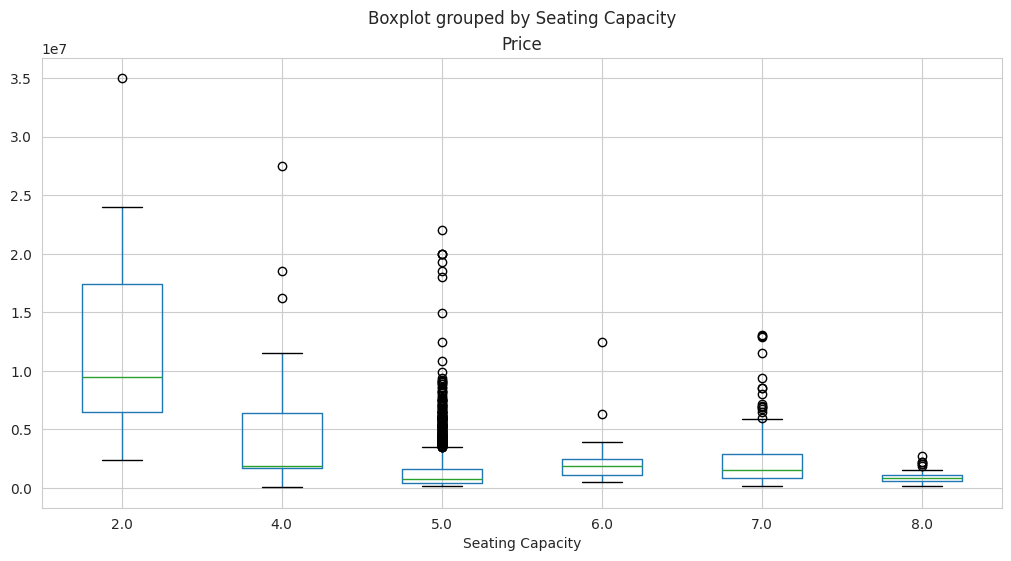

In [95]:
## Two varaible  واحد اساسى والتانى بياثر عليه
df.boxplot(column='Price', by="Seating Capacity" , figsize=(12,6))

In [96]:
seat_price = (
    df.groupby("Drivetrain")['Price']
    .agg(['mean','median','count'])
    .sort_index()
)

print(seat_price)

                    mean     median  count
Drivetrain                                
AWD         4.292919e+06  3450000.0    272
FWD         9.011127e+05   643500.0   1330
RWD         3.153190e+06  2225000.0    321


In [97]:
df['Owner'].value_counts()

,count
Owner,
First,1619
Second,373
Third,42
UnRegistered Car,21
Fourth,3
4 or More,1


In [98]:
seat_price=(
    df.groupby("Owner")['Price']
    .agg(['mean','median','count']) ## Aggregation
    .sort_values(by = ['mean','median','count'], ascending=False)
)

print(seat_price)


                          mean     median  count
Owner                                           
UnRegistered Car  5.285333e+06  5200000.0     21
Third             1.981929e+06   399500.0     42
First             1.714159e+06   849000.0   1619
Second            1.438051e+06   775000.0    373
Fourth            1.633333e+05   160000.0      3
4 or More         1.200000e+05   120000.0      1


In [99]:
Engine_price = (
    df.groupby("Engine")["Price"].agg(["mean", "median", "count"]).sort_index()
)

Engine_price

,mean,median,count
Engine,,,
1047 cc,434500.000000,434500.0,2
1061 cc,170600.000000,160000.0,5
1086 cc,306814.629630,250000.0,27
1120 cc,410333.333333,420500.0,6
1186 cc,418749.500000,439999.5,4
...,...,...,...
814 cc,261153.846154,250000.0,13
936 cc,229999.000000,229999.0,1
995 cc,190000.000000,190000.0,1


In [100]:
Max_Power_price = (
    df.groupby("Max Power")["Price"].agg(["mean", "median", "count"]).sort_index()
)

print(Max_Power_price)

                            mean     median  count
Max Power                                         
100 bhp @ 3600 rpm  1.013333e+06  1000000.0      3
100 bhp @ 3750 rpm  6.162856e+05   630000.0      7
100@5500            3.100000e+05   310000.0      1
101 bhp @ 3600 rpm  9.247498e+05   921999.5      4
102@5500            2.550000e+05   255000.0      2
...                          ...        ...    ...
98 bhp @ 6000 rpm   3.150000e+05   315000.0      1
99 bhp @ 3600 rpm   5.920417e+05   545000.0     24
99 bhp @ 3750 rpm   6.368462e+05   620000.0     13
99 bhp @ 4000 rpm   1.000667e+06  1080000.0      3
99 bhp @ 5000 rpm   8.000000e+05   800000.0      1

[335 rows x 3 columns]


In [101]:
units=(
     df["Max Power"].astype(str).str.replace(r"[0-9\.]", "", regex=True).str.strip().unique()
)

print("Units found in dataset:")
print(units)
## Str.strip() بتمسح المسافات الفاضيه فى اول الجمله وفى اخرها
## str.replace  دى اللتبديل

Units found in dataset:
['bhp @  rpm' 'nan' '@' 'bhp @']


In [102]:
units=(
    df['Max Torque'].astype(str).str.replace(r"[0-9\.]","",regex=True).str.strip().unique() )

print("Units found in dataset:")
print(units)

Units found in dataset:
['Nm @  rpm' 'nan' '@']


In [103]:
units=(
    df['Engine'].astype(str).str.replace(r"[0-9\.]", "", regex=True)
    .str.strip()
    .unique()
)
print("Units found in dataset:")
print(units)

Units found in dataset:
['cc' 'nan']


In [104]:
def true_num(val:str)->float:  ## Function Take Parameter
  if pd.isnull(val):
     return np.nan
  val=str(val).strip()
  val = re.findall(r'\d+\.?\d*',val)

  if val:
    return float(val[0])
  else:
       return np.nan

In [121]:
## Take Parameter
def true_num2(val):
  val= re.sub(r'[^\d]','',val)
  return val

In [122]:
true_num2('123.5 @ 1234')

'12351234'

In [123]:
true_num('123.5 @ 1234')

123.5

In [124]:
#######################################################
# ['Standard' 'Large_Family' 'Coupe' 'Utility' 'Sports'] # This line was causing an IndentationError. It's now commented out.

def categorize_seat(seat:str)->str:
   if pd.isnull(seat):
    return np.nan

   if seat<=2:
    return 'Sports'

   elif seat == 4:
      return 'coupe'

   elif seat == 5:
      return 'Standard'
   elif seat in [6,7]:
      return 'large_family'
   elif seat >= 8:
        return "Utility"
   else:
        return "Other"

In [125]:
categorize_seat(5) ##    استخدام ال Functions

'Standard'

In [126]:
clean_df=df.copy()

In [129]:
## Apply +  تطبيق الداله

## Apply(Function)
##  يعنى العمود ده ال نا عاوزه طبقلى الداله دى عليه
clean_df["Engine"]=df[ "Engine"].apply(true_num)
clean_df["Max Power"] = clean_df["Max Power"].apply(true_num)
clean_df["Max Torque"] = clean_df["Max Torque"].apply(true_num)
# Make sure column name matches exactly
clean_df["Car_Class"] = clean_df["Seating Capacity"].apply(categorize_seat)

print(clean_df[["Engine", "Max Power", "Max Torque", "Car_Class"]].head(10))
print("\nUnique Classes Created:", clean_df["Car_Class"].unique())


   Engine  Max Power  Max Torque     Car_Class
0  1198.0       87.0    109.0000      Standard
1  1248.0       74.0    190.0000      Standard
2  1197.0       79.0    112.7619      Standard
3  1197.0       82.0    113.0000      Standard
4  2393.0      148.0    343.0000  large_family
5  1373.0       91.0    130.0000      Standard
6  1991.0      181.0    300.0000      Standard
7  1995.0      188.0    400.0000      Standard
8  1798.0      177.0    250.0000      Standard
9  1461.0       84.0    200.0000      Standard

Unique Classes Created: ['Standard' 'large_family' 'coupe' nan 'Utility' 'Sports']


In [ ]:
clean_df = df.copy()

In [157]:
# Re-apply numerical conversions and car class categorization to clean_df
clean_df["Engine"]=df[ "Engine"].apply(true_num)
clean_df["Max Power"] = clean_df["Max Power"].apply(true_num)
clean_df["Max Torque"] = clean_df["Max Torque"].apply(true_num)
clean_df["Car_Class"] = clean_df["Seating Capacity"].apply(categorize_seat)

# Re-create df_lazy by dropping critical missing values from clean_df
df_lazy = drop_critical_missing(clean_df, critical_features)

 Missing Data Report:
   Original Rows: 2059
   Rows Dropped : 185 (8.98%)
   Remaining    : 1874


In [158]:
# Re-create df_smart as a copy of df_lazy
df_smart = df_lazy.copy()

In [159]:
q1=df['Price'].quantile(.25)
q3=df['Price'].quantile(.75)
IQR=q3-q1

lowwer_bound = q1- 3*IQR
upper_bound  = q3 + 3*IQR

print(f"price outlier bounds(IQR methods):")
print(f"  lower_bound:{lowwer_bound:,.0f}")
print(f"  upper_bound:{upper_bound:,.0f}")


## Apply to both data base
before_lazy = df_lazy.shape[0]
before_smart = df_smart.shape[0]

df_lazy = df_lazy[
    (df_lazy["Price"] >= max(0, lowwer_bound)) & (df_lazy["Price"] <= upper_bound)
]
df_smart = df_smart[
    (df_smart["Price"] >= max(0, lowwer_bound)) & (df_smart["Price"] <= upper_bound)
]


print(f"\nAfter removing price outliers:")
print(
    f"  Dataset A (Lazy):  {df_lazy.shape[0]} rows (removed {before_lazy - df_lazy.shape[0]})"
)
print(
    f"  Dataset B (Smart): {df_smart.shape[0]} rows (removed {before_smart - df_smart.shape[0]})"
)


price outlier bounds(IQR methods):
  lower_bound:-3,835,004
  upper_bound:6,245,003

After removing price outliers:
  Dataset A (Lazy):  1795 rows (removed 79)
  Dataset B (Smart): 1795 rows (removed 79)


In [ ]:
# Re-display the distribution of Price after outlier removal
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

## Histogram
axes[0].hist(df_smart["Price"], bins=50, edgecolor="black")
axes[0].set_title("Distribution of Prices (Outliers Removed)")
axes[0].set_xlabel("Price")
axes[0].set_ylabel("Frequency")

## Boxplot
axes[1].boxplot(df_smart["Price"])
axes[1].set_title("Boxplot: Prices after Outlier Removal")
axes[1].set_ylabel("Price")

plt.tight_layout()
plt.show()
print(f"\nPrice statistics after outlier removal:")
print(df_smart["Price"].describe())

In [132]:
def drop_critical_missing(df: pd.DataFrame, critical_cols: list) -> pd.DataFrame:
    """
    Drops rows only if they have missing values in the specified critical columns.
    Prints a report of how much data was lost.
    """
    initial_count = df.shape[0]
    df_clean = df.dropna(subset=critical_cols).copy()
    final_count = df_clean.shape[0]
    rows_lost = initial_count - final_count
    percent_lost = (rows_lost / initial_count) * 100 if initial_count > 0 else 0

    print(f" Missing Data Report:")
    print(f"   Original Rows: {initial_count}")
    print(f"   Rows Dropped : {rows_lost} ({percent_lost:.2f}%)")
    print(f"   Remaining    : {final_count}")
    return df_clean


critical_features = [
    "Price",
    "Year",
    "Kilometer",
    "Engine",
    "Max Power",
    "Fuel Type",
    "Transmission",
    "Drivetrain",
    "Fuel Tank Capacity"
]

df_lazy = drop_critical_missing(clean_df, critical_features)

 Missing Data Report:
   Original Rows: 2059
   Rows Dropped : 185 (8.98%)
   Remaining    : 1874


In [133]:
df_lazy.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1874 entries, 0 to 2057
Data columns (total 21 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Make                1874 non-null   object 
 1   Model               1874 non-null   object 
 2   Price               1874 non-null   int64  
 3   Year                1874 non-null   int64  
 4   Kilometer           1874 non-null   int64  
 5   Fuel Type           1874 non-null   object 
 6   Transmission        1874 non-null   object 
 7   Location            1874 non-null   object 
 8   Color               1874 non-null   object 
 9   Owner               1874 non-null   object 
 10  Seller Type         1874 non-null   object 
 11  Engine              1874 non-null   float64
 12  Max Power           1874 non-null   float64
 13  Max Torque          1874 non-null   float64
 14  Drivetrain          1874 non-null   object 
 15  Length              1874 non-null   float64
 16  Width      

In [137]:
df_smart = df_lazy.copy() # Temporary fix: Initialize df_smart for now
df_smart.isna().sum()

,0
Make,0
Model,0
Price,0
Year,0
Kilometer,0
Fuel Type,0
Transmission,0
Location,0
Color,0
Owner,0


In [138]:
###############################################################################################
print("\n STRATEGY COMPARISON")
print("=" * 70)
print(f"Original dataset:        {clean_df.shape[0]:>6} rows")
print(
    f"Strategy A (Lazy):       {df_lazy.shape[0]:>6} rows ({(df_lazy.shape[0]/clean_df.shape[0]*100):.1f}%)"
)
print(
    f"Strategy B (Smart):      {df_smart.shape[0]:>6} rows ({(df_smart.shape[0]/clean_df.shape[0]*100):.1f}%)"
)
print("=" * 70)
print(f"\nData saved by Strategy B: {df_smart.shape[0] - df_lazy.shape[0]} rows")
###############################################################################################


 STRATEGY COMPARISON
Original dataset:          2059 rows
Strategy A (Lazy):         1874 rows (91.0%)
Strategy B (Smart):        1874 rows (91.0%)

Data saved by Strategy B: 0 rows


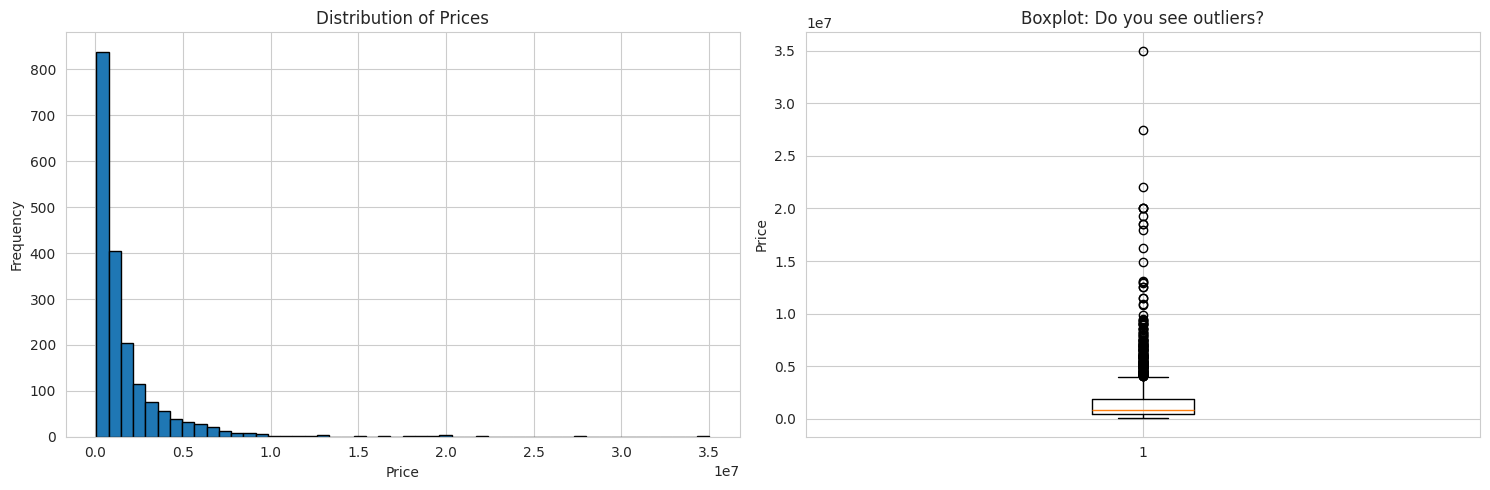


Price statistics:
count    1.874000e+03
mean     1.718279e+06
std      2.426090e+06
min      4.900000e+04
25%      5.000000e+05
50%      8.424995e+05
75%      1.908250e+06
max      3.500000e+07
Name: Price, dtype: float64


In [139]:
# Check the distribution of Price
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

## Histogram
axes[0].hist(df_smart["Price"], bins=50, edgecolor="black")
axes[0].set_title("Distribution of Prices")
axes[0].set_xlabel("Price")
axes[0].set_ylabel("Frequency")

## Boxplot
axes[1].boxplot(df_smart["Price"])
axes[1].set_title("Boxplot: Do you see outliers?")
axes[1].set_ylabel("Price")

plt.tight_layout()
plt.show()
print(f"\nPrice statistics:")
print(df_smart["Price"].describe())



## quantile(.25)      Q1 داله الربع
## quantile(.75)     داله الربع Q2

In [154]:
##  لو عاوز اعرف  الداتا عندى من فين لفين
q1=df['Price'].quantile(.25)
q3=df['Price'].quantile(.75)
IQR=q3-q1

lowwer_bound = q1- 3*IQR
upper_bound  = q3 + 3*IQR

print(f"price outlier bounds(IQR methods):")
print(f"  lower_bound:{lowwer_bound:,.0f}")
print(f"  upper_bound:{upper_bound:,.0f}")


## Apply to both data base
before_lazy = df_lazy.shape[0]
before_smart = df_smart.shape[0]

df_lazy = df_lazy[
    (df_lazy["Price"] >= max(0, lowwer_bound)) & (df_lazy["Price"] <= upper_bound)
]
df_smart = df_smart[
    (df_smart["Price"] >= max(0, lowwer_bound)) & (df_smart["Price"] <= upper_bound)
]


print(f"\nAfter removing price outliers:")
print(
    f"  Dataset A (Lazy):  {df_lazy.shape[0]} rows (removed {before_lazy - df_lazy.shape[0]})"
)
print(
    f"  Dataset B (Smart): {df_smart.shape[0]} rows (removed {before_smart - df_smart.shape[0]})"
)


price outlier bounds(IQR methods):
  lower_bound:-3,835,004
  upper_bound:6,245,003

After removing price outliers:
  Dataset A (Lazy):  0 rows (removed 0)
  Dataset B (Smart): 0 rows (removed 0)


In [147]:
df_lazy.info()


<class 'pandas.core.frame.DataFrame'>
Index: 0 entries
Data columns (total 21 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Make                0 non-null      object 
 1   Model               0 non-null      object 
 2   Price               0 non-null      int64  
 3   Year                0 non-null      int64  
 4   Kilometer           0 non-null      int64  
 5   Fuel Type           0 non-null      object 
 6   Transmission        0 non-null      object 
 7   Location            0 non-null      object 
 8   Color               0 non-null      object 
 9   Owner               0 non-null      object 
 10  Seller Type         0 non-null      object 
 11  Engine              0 non-null      float64
 12  Max Power           0 non-null      float64
 13  Max Torque          0 non-null      float64
 14  Drivetrain          0 non-null      object 
 15  Length              0 non-null      float64
 16  Width               0 non

In [149]:
# Define feature sets
numeric_features=[
 "Year",
    "Kilometer",
    "Engine",
    "Max Torque",
    "Max Power",
    "Seating Capacity",
    "Length",
    "Width",
    "Height",
    "Fuel Tank Capacity",
]
categorical_features = ["Fuel Type", "Transmission", "Owner", "Seller Type",  "Car_Class"]

# We drop: Make, Model, Location, Color, Drivetrain (optional for advanced version)

all_features = numeric_features + categorical_features
target = "Price"

print('Feature Selected:')
print(f"   Numeric ({len(numeric_features)}):{numeric_features}")
print(f" categorical ({len(categorical_features)}):{categorical_features} "  )
print(f"  Target:{target}")


Feature Selected:
   Numeric (10):['Year', 'Kilometer', 'Engine', 'Max Torque', 'Max Power', 'Seating Capacity', 'Length', 'Width', 'Height', 'Fuel Tank Capacity']
 categorical (5):['Fuel Type', 'Transmission', 'Owner', 'Seller Type', 'Car_Class'] 
  Target:Price


In [150]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        (
            "cat",
            OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False),
            categorical_features,
        ),
    ],
    remainder="drop",
)
def create_pipeline():
    return Pipeline(
        steps=[("preprocessor", preprocessor), ("regressor", LinearRegression())]
    )

In [151]:
def evaluate_model(df, dataset_name):
    """
    Train and evaluate a Linear Regression model using sklearn Pipeline.

    Parameters:
    -----------
    df : DataFrame
        The dataset to use
    dataset_name : str
        Name for display purposes

    Returns:
    --------
    dict : Dictionary containing model, metrics, and predictions
    """
    # Prepare features and target
    X = df[all_features]
    y = df[target]

    # Train/test split
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    print(f"\n{'='*70}")
    print(f"Training Model: {dataset_name}")
    print(f"{'='*70}")
    print(f"Training set: {X_train.shape[0]:,} rows")
    print(f"Test set:     {X_test.shape[0]:,} rows")

    # Create and train pipeline
    model_pipeline = create_pipeline()
    model_pipeline.fit(X_train, y_train)
    print("✓ Model trained successfully")

    # Predictions
    y_pred_train = model_pipeline.predict(X_train)
    y_pred_test = model_pipeline.predict(X_test)
# Calculate metrics
    train_r2 = r2_score(y_train, y_pred_train)
    test_r2 = r2_score(y_test, y_pred_test)
    train_rmse = np.sqrt(mean_squared_error(y_train, y_pred_train))
    test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
    test_mae = mean_absolute_error(y_test, y_pred_test)

    # Display results
    print(f"\ Performance Metrics:")
    print(f"{'-'*70}")
    print(f"{'Metric':<25} {'Train':<20} {'Test':<20}")
    print(f"{'-'*70}")
    print(f"{'R² Score':<25} {train_r2:<20.4f} {test_r2:<20.4f}")
    print(f"{'RMSE':<25} {train_rmse:<20,.2f} {test_rmse:<20,.2f}")
    print(f"{'MAE':<25} {'':<20} {test_mae:<20,.2f}")
    print(f"{'-'*70}")

# Overfitting check
    overfit_score = train_r2 - test_r2
    if overfit_score > 0.1:
        print(f"  Warning: Possible overfitting (difference = {overfit_score:.3f})")
    else:
        print(f" Good generalization (difference = {overfit_score:.3f})")

    return {
        "name": dataset_name,
        "pipeline": model_pipeline,
        "train_r2": train_r2,
        "test_r2": test_r2,
        "train_rmse": train_rmse,
           "test_rmse": test_rmse,
        "test_mae": test_mae,
        "y_test": y_test,
        "y_pred": y_pred_test,
    }


print("\n Evaluation function defined")


 Evaluation function defined


In [160]:
results_lazy = evaluate_model(df_lazy, "Dataset A (Lazy - Dropped NaNs)")



Training Model: Dataset A (Lazy - Dropped NaNs)
Training set: 1,436 rows
Test set:     359 rows
✓ Model trained successfully
\ Performance Metrics:
----------------------------------------------------------------------
Metric                    Train                Test                
----------------------------------------------------------------------
R² Score                  0.7829               0.7684              
RMSE                      595,678.08           651,738.46          
MAE                                            441,953.43          
----------------------------------------------------------------------
 Good generalization (difference = 0.014)


In [161]:
results_smart = evaluate_model(df_smart, "Dataset B (Smart - Imputed NaNs)")



Training Model: Dataset B (Smart - Imputed NaNs)
Training set: 1,436 rows
Test set:     359 rows
✓ Model trained successfully
\ Performance Metrics:
----------------------------------------------------------------------
Metric                    Train                Test                
----------------------------------------------------------------------
R² Score                  0.7829               0.7684              
RMSE                      595,678.08           651,738.46          
MAE                                            441,953.43          
----------------------------------------------------------------------
 Good generalization (difference = 0.014)
